# CTD Analysis

This notebook reads CTD data from the South Fork Wind field work legs. Raw data are ingested, cleaned, and plotted.

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from rodeo.plotting import plot_ctd_profiles
from rodeo.utils import clean_ctd_data

plt.style.use(Path.cwd() / "config" / "jasa_fig_style.mplstyle")

## Read CTD data

In [19]:
dates = [
    "2023-06-23",
    "2023-07-23",
    "2023-08-01",
    "2023-08-12",
]

ctd_files = [
    # Path("data/ctd/sfw_leg1_2023-06-23/Casts/203246_20230624_0930_data.txt"),
    # Path("data/ctd/sfw_leg1_2023-06-23/Casts/208910_20230624_0555_data.txt"),
    Path("data/ctd/sfw_leg1_2023-06-23/Casts/RBR203246_data.txt"),
    Path("data/ctd/sfw_leg2_2023-07-23/CTD_cast_south_fork_07_23_2023_data.txt"),
    Path("data/ctd/sfw_leg3_2023-08-01/RBR203246_data.txt"),
    Path("data/ctd/sfw_leg4_2023-08-12/CTD_Casts/RBR203246_data.txt"),
]

dfs = [clean_ctd_data(pd.read_csv(f, parse_dates=["Time"]), min_depth=1.0) for f in ctd_files]



## Plot all profiles

In [ ]:
for i, df in enumerate(dfs):
    plot_kwargs = {
        "Temperature": {"label": "Temperature", "color": "black"},
        "Salinity": {"label": "Salinity", "color": "black"},
        "Speed of sound": {"label": "Speed of sound", "color": "black"},
    }
    fig = plot_ctd_profiles(df, **plot_kwargs)
    fig.suptitle(f"{dates[i]}")

## Plot profile of interest

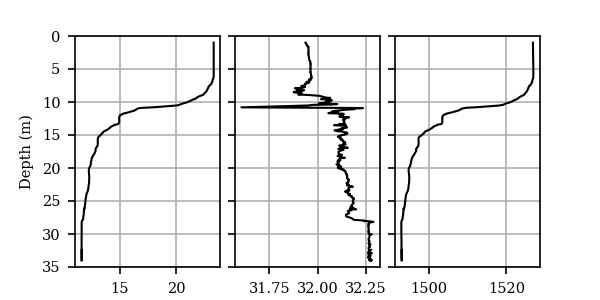

In [21]:
df = dfs[1]

# Find where the difference in depths changes sign:
depth_diff = df["Depth"].diff()
depth_diff_sign_change = depth_diff[depth_diff * depth_diff.shift(-1) < 0].index
# Find the index of the first occurrence of the sign change:
first_sign_change = depth_diff_sign_change[0]
# Create a new DataFrame with the first sign change:
df = df.iloc[:first_sign_change]

plot_kwargs = {
    "figsize": (4, 2),
    "Temperature": {"label": "Temperature", "color": "black"},
    "Salinity": {"label": "Salinity", "color": "black"},
    "Speed of sound": {"label": "Speed of sound", "color": "black"},
    "gridspec_kw": {"wspace": 0.1},
}
fig = plot_ctd_profiles(df, **plot_kwargs)
fig.savefig("results/ctd.png", dpi=600, bbox_inches="tight", facecolor="white")